In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATASET_DIR = "/content/drive/MyDrive/D_Rdatasets"

TRAIN_DIR = os.path.join(DATASET_DIR, "train_images")
TEST_DIR = os.path.join(DATASET_DIR, "test_images")
VAL_DIR = os.path.join(DATASET_DIR, "val_images")

TRAIN_CSV = os.path.join(DATASET_DIR, "train_1.csv")
TEST_CSV = os.path.join(DATASET_DIR, "test.csv")
VAL_CSV = os.path.join(DATASET_DIR, "valid.csv")

print("Dataset directory:", DATASET_DIR)

Dataset directory: /content/drive/MyDrive/D_Rdatasets


In [ ]:
paths = {
    "Main Dataset": DATASET_DIR,
    "Training Images": TRAIN_DIR,
    "Testing Images": TEST_DIR,
    "Validation Images": VAL_DIR,
    "Training CSV": TRAIN_CSV,
    "Testing CSV": TEST_CSV,
    "Validation CSV": VAL_CSV
}

for name, path in paths.items():
    if os.path.exists(path):
        print("FOUND:", name)
    else:
        print("MISSING:", name)

FOUND: Main Dataset
FOUND: Training Images
FOUND: Testing Images
FOUND: Validation Images
FOUND: Training CSV
FOUND: Testing CSV
FOUND: Validation CSV


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter
import os
import random
import hashlib
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
val_df = pd.read_csv(VAL_CSV)

print("TRAIN DATASET")
display(train_df.head())

print("TEST DATASET")
display(test_df.head())

print("VALIDATION DATASET")
display(val_df.head())

TRAIN DATASET


,id_code,diagnosis
0,1ae8c165fd53,2
1,1b329a127307,1
2,1b32e1d775ea,4
3,1b3647865779,0
4,1b398c0494d1,0


TEST DATASET


,id_code,diagnosis
0,e4dcca36ceb4,0
1,e4e343eaae2a,2
2,e4f12411fd85,4
3,e50b0174690d,0
4,e5197d77ec68,0


VALIDATION DATASET


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [ ]:
datasets = {
    "TRAIN": train_df,
    "TEST": test_df,
    "VALIDATION": val_df
}

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name, "DATASET")
    print("=" * 60)

    print("Number of rows:", len(df))
    print("Number of columns:", len(df.columns))

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nData types:")
    print(df.dtypes)


TRAIN DATASET
Number of rows: 2930
Number of columns: 2

Column names:
['id_code', 'diagnosis']

Missing values:
id_code      0
diagnosis    0
dtype: int64

Data types:
id_code      object
diagnosis     int64
dtype: object

TEST DATASET
Number of rows: 366
Number of columns: 2

Column names:
['id_code', 'diagnosis']

Missing values:
id_code      0
diagnosis    0
dtype: int64

Data types:
id_code      object
diagnosis     int64
dtype: object

VALIDATION DATASET
Number of rows: 366
Number of columns: 2

Column names:
['id_code', 'diagnosis']

Missing values:
id_code      0
diagnosis    0
dtype: int64

Data types:
id_code      object
diagnosis     int64
dtype: object


In [ ]:
for name, df in datasets.items():

    print("\n", "=" * 50)
    print(name, "DATASET")
    print("=" * 50)

    print("Columns:", df.columns.tolist())

    print("\nFirst 10 records:")
    display(df.head(10))


TRAIN DATASET
Columns: ['id_code', 'diagnosis']

First 10 records:


,id_code,diagnosis
0,1ae8c165fd53,2
1,1b329a127307,1
2,1b32e1d775ea,4
3,1b3647865779,0
4,1b398c0494d1,0
5,1b4625877527,2
6,1b495ac025b7,3
7,1b862fb6f65d,0
8,1b8701231c8f,0
9,1b8ad0afe9fb,2



TEST DATASET
Columns: ['id_code', 'diagnosis']

First 10 records:


,id_code,diagnosis
0,e4dcca36ceb4,0
1,e4e343eaae2a,2
2,e4f12411fd85,4
3,e50b0174690d,0
4,e5197d77ec68,0
5,e529c5757d64,0
6,e52ed5c29c5e,3
7,e540d2e35d15,2
8,e55188915f9d,1
9,e580676516b0,1



VALIDATION DATASET
Columns: ['id_code', 'diagnosis']

First 10 records:


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0
5,0083ee8054ee,4
6,0097f532ac9f,0
7,00a8624548a9,2
8,00b74780d31d,2
9,00cb6555d108,1


In [ ]:
for name, df in datasets.items():

    print("\n", "=" * 50)
    print(name, "CLASS ANALYSIS")
    print("=" * 50)

    for col in df.columns:

        print("\nColumn:", col)
        print("Unique values:", df[col].nunique())

        if df[col].nunique() <= 20:
            print(df[col].value_counts(dropna=False))


TRAIN CLASS ANALYSIS

Column: id_code
Unique values: 2930

Column: diagnosis
Unique values: 5
diagnosis
0    1434
2     808
1     300
4     234
3     154
Name: count, dtype: int64

TEST CLASS ANALYSIS

Column: id_code
Unique values: 366

Column: diagnosis
Unique values: 5
diagnosis
0    199
2     87
4     33
1     30
3     17
Name: count, dtype: int64

VALIDATION CLASS ANALYSIS

Column: id_code
Unique values: 366

Column: diagnosis
Unique values: 5
diagnosis
0    172
2    104
1     40
4     28
3     22
Name: count, dtype: int64


diagnosis
0    1434
1     300
2     808
3     154
4     234
Name: count, dtype: int64


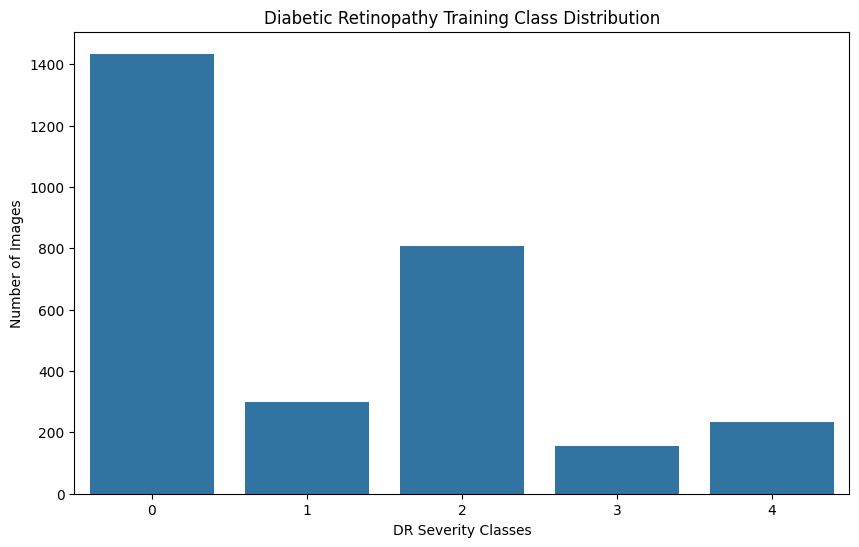

In [ ]:
LABEL_COL = "diagnosis"  # Replace with your actual column name

print(train_df[LABEL_COL].value_counts().sort_index())

plt.figure(figsize=(10, 6))

sns.countplot(
    data=train_df,
    x=LABEL_COL,
    order=sorted(train_df[LABEL_COL].dropna().unique())
)

plt.title("Diabetic Retinopathy Training Class Distribution")
plt.xlabel("DR Severity Classes")
plt.ylabel("Number of Images")

plt.show()

In [ ]:
import os

def count_images(folder):

    extensions = (
        ".jpg", ".jpeg", ".png",
        ".bmp", ".tif", ".tiff"
    )

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(extensions)
    ]

    return len(images)

print("Image counting function is ready!")

Image counting function is ready!


In [ ]:
print("=" * 50)
print("DATASET IMAGE COUNT COMPARISON")
print("=" * 50)

print("\nTRAINING")
print("CSV records:", len(train_df))
print("Images:", count_images(TRAIN_DIR))

print("\nTESTING")
print("CSV records:", len(test_df))
print("Images:", count_images(TEST_DIR))

print("\nVALIDATION")
print("CSV records:", len(val_df))
print("Images:", count_images(VAL_DIR))

DATASET IMAGE COUNT COMPARISON

TRAINING
CSV records: 2930
Images: 0

TESTING
CSV records: 366
Images: 0

VALIDATION
CSV records: 366
Images: 0


In [ ]:
print("TRAIN COLUMNS:", train_df.columns.tolist())
print("TEST COLUMNS:", test_df.columns.tolist())
print("VALIDATION COLUMNS:", val_df.columns.tolist())

TRAIN COLUMNS: ['id_code', 'diagnosis']
TEST COLUMNS: ['id_code', 'diagnosis']
VALIDATION COLUMNS: ['id_code', 'diagnosis']


In [ ]:
IMAGE_COL = "id_code"  # Replace with your actual image column

In [ ]:
def resolve_image(filename, folder):

    filename = str(filename).strip()

    extensions = [
        "", ".jpg", ".jpeg",
        ".png", ".bmp", ".tif", ".tiff"
    ]

    for ext in extensions:

        candidate = os.path.join(folder, filename + ext)

        if os.path.isfile(candidate):
            return candidate

    return None


def check_csv_images(df, folder, image_col):

    found = 0
    missing = []

    for filename in df[image_col]:

        path = resolve_image(filename, folder)

        if path is not None:
            found += 1
        else:
            missing.append(filename)

    print("CSV records:", len(df))
    print("Images found:", found)
    print("Images missing:", len(missing))

    if missing:
        print("\nFirst 10 missing filenames:")
        print(missing[:10])

    return missing

In [ ]:
train_missing = check_csv_images(
    train_df, TRAIN_DIR, IMAGE_COL
)

print("\nTESTING RESULTS")

test_missing = check_csv_images(
    test_df, TEST_DIR, IMAGE_COL
)

print("\nVALIDATION RESULTS")

val_missing = check_csv_images(
    val_df, VAL_DIR, IMAGE_COL
)

CSV records: 2930
Images found: 0
Images missing: 2930

First 10 missing filenames:
['1ae8c165fd53', '1b329a127307', '1b32e1d775ea', '1b3647865779', '1b398c0494d1', '1b4625877527', '1b495ac025b7', '1b862fb6f65d', '1b8701231c8f', '1b8ad0afe9fb']

TESTING RESULTS
CSV records: 366
Images found: 0
Images missing: 366

First 10 missing filenames:
['e4dcca36ceb4', 'e4e343eaae2a', 'e4f12411fd85', 'e50b0174690d', 'e5197d77ec68', 'e529c5757d64', 'e52ed5c29c5e', 'e540d2e35d15', 'e55188915f9d', 'e580676516b0']

VALIDATION RESULTS
CSV records: 366
Images found: 0
Images missing: 366

First 10 missing filenames:
['000c1434d8d7', '001639a390f0', '0024cdab0c1e', '002c21358ce6', '005b95c28852', '0083ee8054ee', '0097f532ac9f', '00a8624548a9', '00b74780d31d', '00cb6555d108']


In [ ]:
from PIL import Image

def check_corrupted_images(folder):

    extensions = (
        ".jpg", ".jpeg", ".png",
        ".bmp", ".tif", ".tiff"
    )

    corrupted = []
    valid = 0

    for filename in os.listdir(folder):

        if filename.lower().endswith(extensions):

            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as img:
                    img.verify()

                valid += 1

            except Exception:
                corrupted.append(filename)

    print("\nFolder:", folder)
    print("Valid images:", valid)
    print("Corrupted images:", len(corrupted))

    return corrupted

In [ ]:
train_corrupted = check_corrupted_images(TRAIN_DIR)

test_corrupted = check_corrupted_images(TEST_DIR)

val_corrupted = check_corrupted_images(VAL_DIR)


Folder: /content/drive/MyDrive/D_Rdatasets/train_images
Valid images: 0
Corrupted images: 0

Folder: /content/drive/MyDrive/D_Rdatasets/test_images
Valid images: 0
Corrupted images: 0

Folder: /content/drive/MyDrive/D_Rdatasets/val_images
Valid images: 0
Corrupted images: 0


In [ ]:
from collections import Counter

def analyse_dimensions(folder):

    dimensions = []

    extensions = (
        ".jpg", ".jpeg", ".png",
        ".bmp", ".tif", ".tiff"
    )

    for filename in os.listdir(folder):

        if filename.lower().endswith(extensions):

            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as img:
                    dimensions.append(img.size)

            except Exception:
                pass

    print("Total readable images:", len(dimensions))

    print("\nMost common dimensions:")

    for dimension, count in Counter(dimensions).most_common(10):
        print(dimension, ":", count)

    return dimensions

In [ ]:
train_dimensions = analyse_dimensions(TRAIN_DIR)

val_dimensions = analyse_dimensions(VAL_DIR)

test_dimensions = analyse_dimensions(TEST_DIR)

Total readable images: 0

Most common dimensions:
Total readable images: 0

Most common dimensions:
Total readable images: 0

Most common dimensions:


In [ ]:
image_files = [
    f for f in os.listdir(TRAIN_DIR)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
    )
]

sample_images = random.sample(
    image_files,
    min(9, len(image_files))
)

plt.figure(figsize=(12, 10))

for i, filename in enumerate(sample_images):

    img = Image.open(
        os.path.join(TRAIN_DIR, filename)
    ).convert("RGB")

    plt.subplot(3, 3, i + 1)

    plt.imshow(img)
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

<Figure size 1200x1000 with 0 Axes>

In [ ]:
def get_filenames(folder):

    extensions = (
        ".jpg", ".jpeg", ".png",
        ".bmp", ".tif", ".tiff"
    )

    return {
        f.lower()
        for f in os.listdir(folder)
        if f.lower().endswith(extensions)
    }


train_files = get_filenames(TRAIN_DIR)
test_files = get_filenames(TEST_DIR)
val_files = get_filenames(VAL_DIR)

print("Train-Test overlap:", len(train_files & test_files))

print("Train-Validation overlap:", len(train_files & val_files))

print("Test-Validation overlap:", len(test_files & val_files))

Train-Test overlap: 0
Train-Validation overlap: 0
Test-Validation overlap: 0


In [ ]:
import hashlib

def calculate_image_hash(path):

    hasher = hashlib.md5()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            hasher.update(chunk)

    return hasher.hexdigest()


def folder_hashes(folder):

    hashes = {}

    for filename in os.listdir(folder):

        path = os.path.join(folder, filename)

        if not os.path.isfile(path):
            continue

        try:
            file_hash = calculate_image_hash(path)
            hashes[file_hash] = filename

        except Exception:
            pass

    return hashes


train_hashes = folder_hashes(TRAIN_DIR)
test_hashes = folder_hashes(TEST_DIR)
val_hashes = folder_hashes(VAL_DIR)

print("Train-Test duplicates:",
      len(set(train_hashes) & set(test_hashes)))

print("Train-Validation duplicates:",
      len(set(train_hashes) & set(val_hashes)))

print("Test-Validation duplicates:",
      len(set(test_hashes) & set(val_hashes)))

Train-Test duplicates: 0
Train-Validation duplicates: 0
Test-Validation duplicates: 0


In [ ]:
import os

folders = {
    "TRAINING": TRAIN_DIR,
    "TESTING": TEST_DIR,
    "VALIDATION": VAL_DIR
}

for name, folder in folders.items():

    print("\n" + "=" * 55)
    print(name, "FOLDER CONTENTS")
    print("=" * 55)

    contents = os.listdir(folder)

    print("Total items:", len(contents))

    print("\nFirst 20 items:")

    for item in contents[:20]:

        path = os.path.join(folder, item)

        if os.path.isdir(path):
            print("[FOLDER]", item)
        else:
            print("[FILE]", item)


TRAINING FOLDER CONTENTS
Total items: 1

First 20 items:
[FOLDER] train_images

TESTING FOLDER CONTENTS
Total items: 1

First 20 items:
[FOLDER] test_images

VALIDATION FOLDER CONTENTS
Total items: 1

First 20 items:
[FOLDER] val_images


In [ ]:
from collections import Counter

image_extensions = (
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff"
)

def inspect_all_files(folder):

    all_files = []
    extension_counts = Counter()

    for root, dirs, files in os.walk(folder):

        for filename in files:

            path = os.path.join(root, filename)

            all_files.append(path)

            extension = os.path.splitext(filename)[1].lower()

            extension_counts[extension or "[NO EXTENSION]"] += 1

    print("\nFolder:", folder)
    print("Total files:", len(all_files))

    print("\nFile extensions:")

    for extension, count in extension_counts.most_common():
        print(extension, ":", count)

    image_files = [
        f for f in all_files
        if os.path.splitext(f)[1].lower() in image_extensions
    ]

    print("\nRecognized image files:", len(image_files))

    print("\nFirst five image paths:")

    for path in image_files[:5]:
        print(path)

    return image_files


train_images_found = inspect_all_files(TRAIN_DIR)
test_images_found = inspect_all_files(TEST_DIR)
val_images_found = inspect_all_files(VAL_DIR)


Folder: /content/drive/MyDrive/D_Rdatasets/train_images
Total files: 2930

File extensions:
.png : 2930

Recognized image files: 2930

First five image paths:
/content/drive/MyDrive/D_Rdatasets/train_images/train_images/a15590a7d774.png
/content/drive/MyDrive/D_Rdatasets/train_images/train_images/a150ff5dfe07.png
/content/drive/MyDrive/D_Rdatasets/train_images/train_images/a14bbd9a583e.png
/content/drive/MyDrive/D_Rdatasets/train_images/train_images/a125377fb985.png
/content/drive/MyDrive/D_Rdatasets/train_images/train_images/a15470303941.png

Folder: /content/drive/MyDrive/D_Rdatasets/test_images
Total files: 366

File extensions:
.png : 366

Recognized image files: 366

First five image paths:
/content/drive/MyDrive/D_Rdatasets/test_images/test_images/e4dcca36ceb4.png
/content/drive/MyDrive/D_Rdatasets/test_images/test_images/e4e343eaae2a.png
/content/drive/MyDrive/D_Rdatasets/test_images/test_images/e529c5757d64.png
/content/drive/MyDrive/D_Rdatasets/test_images/test_images/e52ed5c

In [ ]:
def match_images_recursive(df, folder, image_col):

    image_map = {}

    for root, dirs, files in os.walk(folder):

        for filename in files:

            stem, ext = os.path.splitext(filename)

            if ext.lower() in image_extensions:

                image_map[stem.lower()] = os.path.join(
                    root, filename
                )

    matched = 0
    missing = []

    for image_id in df[image_col].astype(str):

        if image_id.strip().lower() in image_map:
            matched += 1
        else:
            missing.append(image_id)

    print("\nCSV records:", len(df))
    print("Matched images:", matched)
    print("Missing images:", len(missing))

    return image_map, missing


train_image_map, train_missing = match_images_recursive(
    train_df, TRAIN_DIR, "id_code"
)

test_image_map, test_missing = match_images_recursive(
    test_df, TEST_DIR, "id_code"
)

val_image_map, val_missing = match_images_recursive(
    val_df, VAL_DIR, "id_code"
)


CSV records: 2930
Matched images: 2930
Missing images: 0

CSV records: 366
Matched images: 366
Missing images: 0

CSV records: 366
Matched images: 366
Missing images: 0


In [ ]:
from PIL import Image
import os

def validate_image_integrity(image_map):

    valid_images = []
    corrupted_images = []

    for image_id, path in image_map.items():

        try:
            with Image.open(path) as img:
                img.verify()

            valid_images.append(path)

        except Exception as e:
            corrupted_images.append({
                "image": image_id,
                "error": str(e)
            })

    print("Total images:", len(image_map))
    print("Valid images:", len(valid_images))
    print("Corrupted images:", len(corrupted_images))

    return valid_images, corrupted_images


train_valid, train_corrupt = validate_image_integrity(train_image_map)

test_valid, test_corrupt = validate_image_integrity(test_image_map)

val_valid, val_corrupt = validate_image_integrity(val_image_map)

Total images: 2930
Valid images: 2930
Corrupted images: 0
Total images: 366
Valid images: 366
Corrupted images: 0
Total images: 366
Valid images: 366
Corrupted images: 0


In [ ]:
from collections import Counter

def check_image_dimensions(image_map):

    dimensions = []
    modes = Counter()

    for image_id, path in image_map.items():

        try:
            with Image.open(path) as img:

                dimensions.append(img.size)
                modes[img.mode] += 1

        except Exception:
            pass

    print("Total readable images:", len(dimensions))

    print("\nMost common image dimensions:")

    for size, count in Counter(dimensions).most_common(10):
        print(size, ":", count)

    print("\nImage colour modes:")
    print(modes)

    return dimensions


train_dimensions = check_image_dimensions(train_image_map)

test_dimensions = check_image_dimensions(test_image_map)

val_dimensions = check_image_dimensions(val_image_map)

Total readable images: 2930

Most common image dimensions:
(1050, 1050) : 782
(2416, 1736) : 512
(2588, 1958) : 415
(3216, 2136) : 333
(2048, 1536) : 280
(819, 614) : 232
(3388, 2588) : 113
(1504, 1000) : 72
(1844, 1226) : 47
(4288, 2848) : 38

Image colour modes:
Counter({'RGB': 2930})
Total readable images: 366

Most common image dimensions:
(1050, 1050) : 109
(2416, 1736) : 63
(2588, 1958) : 51
(3216, 2136) : 38
(2048, 1536) : 34
(819, 614) : 30
(3388, 2588) : 14
(1504, 1000) : 12
(2896, 1944) : 5
(1844, 1226) : 4

Image colour modes:
Counter({'RGB': 366})
Total readable images: 366

Most common image dimensions:
(1050, 1050) : 83
(2588, 1958) : 67
(2416, 1736) : 63
(3216, 2136) : 39
(2048, 1536) : 37
(819, 614) : 25
(3388, 2588) : 14
(4288, 2848) : 12
(1844, 1226) : 10
(1504, 1000) : 8

Image colour modes:
Counter({'RGB': 366})


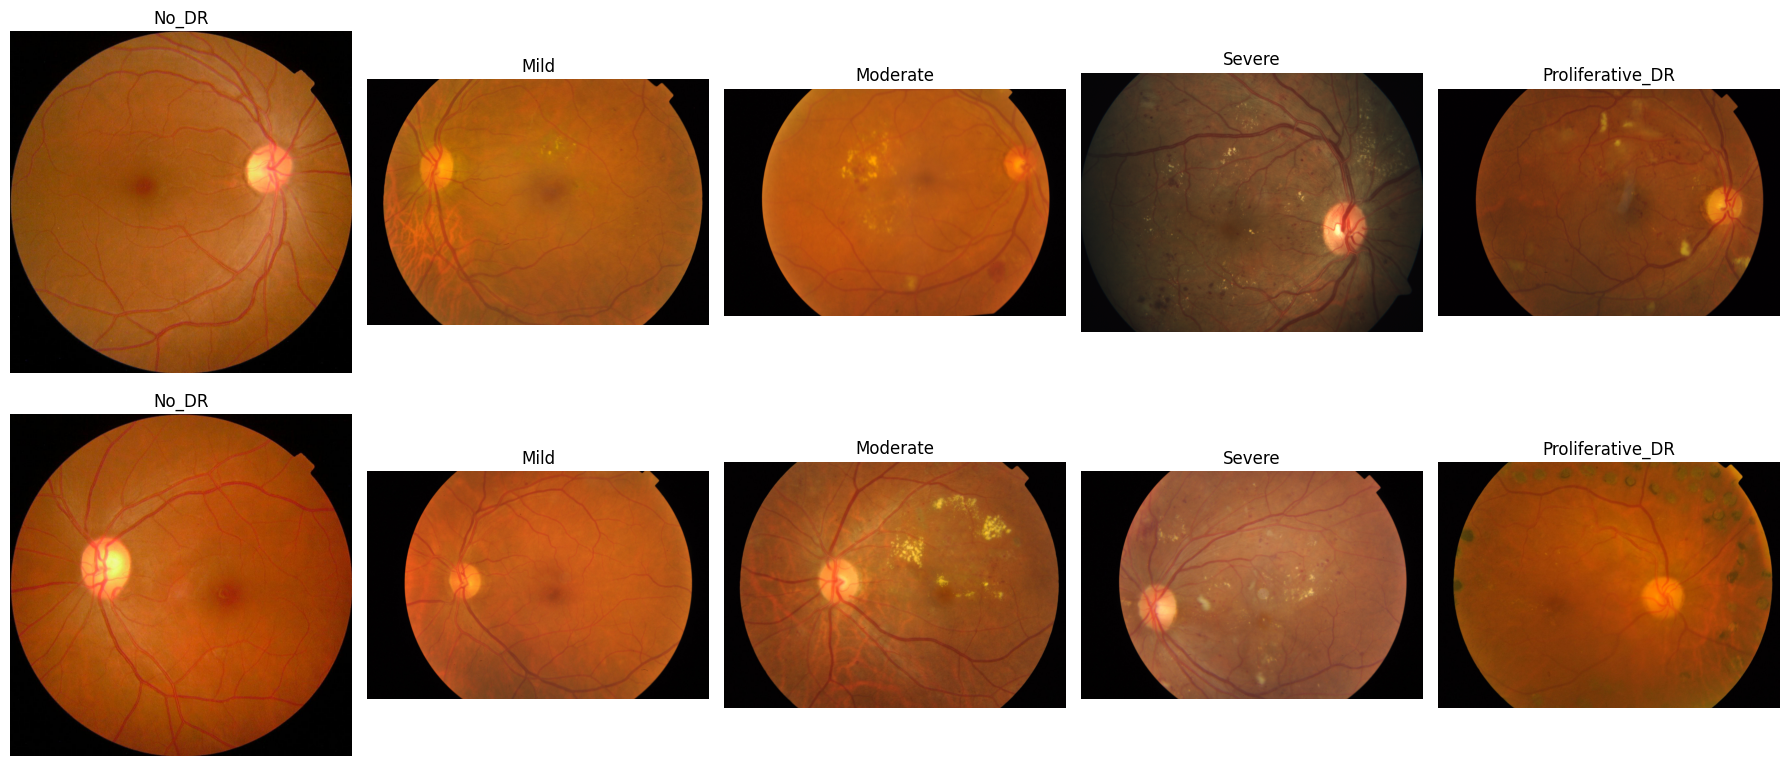

In [ ]:
import matplotlib.pyplot as plt
import random

class_names = {
    0: "No_DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative_DR"
}

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for class_id in range(5):

    class_data = train_df[
        train_df["diagnosis"] == class_id
    ]

    sample = class_data.sample(
        n=min(2, len(class_data))
    )

    for row, (_, record) in enumerate(sample.iterrows()):

        image_id = record["id_code"]

        image_path = train_image_map[image_id.lower()]

        img = Image.open(image_path).convert("RGB")

        axes[row, class_id].imshow(img)

        axes[row, class_id].set_title(
            class_names[class_id]
        )

        axes[row, class_id].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("TRAIN duplicate IDs:",
      train_df["id_code"].duplicated().sum())

print("TEST duplicate IDs:",
      test_df["id_code"].duplicated().sum())

print("VALIDATION duplicate IDs:",
      val_df["id_code"].duplicated().sum())

print("\nCross-dataset ID overlap:")

print("Train-Test:",
      len(set(train_df["id_code"]) & set(test_df["id_code"])))

print("Train-Validation:",
      len(set(train_df["id_code"]) & set(val_df["id_code"])))

print("Test-Validation:",
      len(set(test_df["id_code"]) & set(val_df["id_code"])))

TRAIN duplicate IDs: 0
TEST duplicate IDs: 0
VALIDATION duplicate IDs: 0

Cross-dataset ID overlap:
Train-Test: 0
Train-Validation: 0
Test-Validation: 0


In [ ]:
import hashlib

def image_hash_map(image_map):

    hashes = {}

    for image_id, path in image_map.items():

        with open(path, "rb") as f:

            digest = hashlib.md5(f.read()).hexdigest()

        hashes[digest] = image_id

    return hashes


train_hashes = image_hash_map(train_image_map)
test_hashes = image_hash_map(test_image_map)
val_hashes = image_hash_map(val_image_map)

print("Train-Test duplicates:",
      len(set(train_hashes) & set(test_hashes)))

print("Train-Validation duplicates:",
      len(set(train_hashes) & set(val_hashes)))

print("Test-Validation duplicates:",
      len(set(test_hashes) & set(val_hashes)))

Train-Test duplicates: 22
Train-Validation duplicates: 22
Test-Validation duplicates: 2


In [ ]:
# Find exact duplicate images across datasets

train_test_duplicates = (
    set(train_hashes.keys()) & set(test_hashes.keys())
)

train_val_duplicates = (
    set(train_hashes.keys()) & set(val_hashes.keys())
)

test_val_duplicates = (
    set(test_hashes.keys()) & set(val_hashes.keys())
)

print("TRAIN-TEST DUPLICATES:")
for h in train_test_duplicates:
    print(train_hashes[h], "<->", test_hashes[h])

print("\nTRAIN-VALIDATION DUPLICATES:")
for h in train_val_duplicates:
    print(train_hashes[h], "<->", val_hashes[h])

print("\nTEST-VALIDATION DUPLICATES:")
for h in test_val_duplicates:
    print(test_hashes[h], "<->", val_hashes[h])

TRAIN-TEST DUPLICATES:
bcdc8db5423b <-> f920ccd926db
4fecf87184e6 <-> f7edc074f06b
60f15dd68d30 <-> fcc6aa6755e6
bb7e0a2544cd <-> e76a9cbb2a8c
278aa860dffd <-> f066db7a2efe
3f44d749cd0b <-> f9e1c439d4c8
ce887b196c23 <-> e7a7187066ad
98f7136d2e7a <-> e740af6ac6ea
80d24897669f <-> fea14b3d44b0
ca0f1a17c8e5 <-> ea05c22d92e9
d28bd830c171 <-> f9ecf1795804
b8ac328009e0 <-> ff0740cb484a
ba735b286d62 <-> ed3a0fc5b546
7877be80901c <-> ee2c2a5f7d0e
1c9c583c10bf <-> ea15a290eb96
23d7ca170bdb <-> ea9e0fb6fb0b
1e9224ccca95 <-> f6f3ea0d2693
5dc23e440de3 <-> f4d3777f2710
43fb6eda9b97 <-> e4e343eaae2a
6c3745a222da <-> eadc57064154
521d3e264d71 <-> fe0fc67c7980
9a3c03a5ad0f <-> f03d3c4ce7fb

TRAIN-VALIDATION DUPLICATES:
435d900fa7b2 <-> 1006345f70b7
a75bab2463d4 <-> 1632c4311fc9
ca25745942b0 <-> 00cb6555d108
1e143fa3de57 <-> 144b01e7b993
92b0d27fc0ec <-> 1a1b4b2450ca
cac40227d3b2 <-> 0161338f53cc
ba2624883599 <-> 14515b8f19b6
2c2aa057afc5 <-> 135575dc57c9
4a44cc840ebe <-> 0cb14014117d
65c958379680 <-> 

In [ ]:

# Create a lookup for image ID and its diagnosis

train_labels = dict(zip(
    train_df["id_code"].astype(str),
    train_df["diagnosis"]
))

test_labels = dict(zip(
    test_df["id_code"].astype(str),
    test_df["diagnosis"]
))

val_labels = dict(zip(
    val_df["id_code"].astype(str),
    val_df["diagnosis"]
))

# Compare diagnosis labels for duplicated images

def check_duplicate_labels(duplicates, first_hashes,
                           second_hashes, first_labels,
                           second_labels, split_names):

    same_label = 0
    different_label = 0

    print("\n", split_names)

    for h in duplicates:
        id1 = first_hashes[h]
        id2 = second_hashes[h]

        label1 = first_labels[id1]
        label2 = second_labels[id2]

        if label1 == label2:
            same_label += 1
            status = "SAME LABEL"
        else:
            different_label += 1
            status = "DIFFERENT LABEL"

        print(
            id1, "Diagnosis:", label1,
            "<->",
            id2, "Diagnosis:", label2,
            "|", status
        )

    print("Same labels:", same_label)
    print("Different labels:", different_label)


check_duplicate_labels(
    train_test_duplicates,
    train_hashes, test_hashes,
    train_labels, test_labels,
    "TRAIN-TEST"
)

check_duplicate_labels(
    train_val_duplicates,
    train_hashes, val_hashes,
    train_labels, val_labels,
    "TRAIN-VALIDATION"
)

check_duplicate_labels(
    test_val_duplicates,
    test_hashes, val_hashes,
    test_labels, val_labels,
    "TEST-VALIDATION"
)



 TRAIN-TEST
bcdc8db5423b Diagnosis: 2 <-> f920ccd926db Diagnosis: 2 | SAME LABEL
4fecf87184e6 Diagnosis: 3 <-> f7edc074f06b Diagnosis: 2 | DIFFERENT LABEL
60f15dd68d30 Diagnosis: 4 <-> fcc6aa6755e6 Diagnosis: 3 | DIFFERENT LABEL
bb7e0a2544cd Diagnosis: 3 <-> e76a9cbb2a8c Diagnosis: 3 | SAME LABEL
278aa860dffd Diagnosis: 1 <-> f066db7a2efe Diagnosis: 0 | DIFFERENT LABEL
3f44d749cd0b Diagnosis: 0 <-> f9e1c439d4c8 Diagnosis: 0 | SAME LABEL
ce887b196c23 Diagnosis: 2 <-> e7a7187066ad Diagnosis: 2 | SAME LABEL
98f7136d2e7a Diagnosis: 2 <-> e740af6ac6ea Diagnosis: 4 | DIFFERENT LABEL
80d24897669f Diagnosis: 1 <-> fea14b3d44b0 Diagnosis: 1 | SAME LABEL
ca0f1a17c8e5 Diagnosis: 2 <-> ea05c22d92e9 Diagnosis: 2 | SAME LABEL
d28bd830c171 Diagnosis: 2 <-> f9ecf1795804 Diagnosis: 2 | SAME LABEL
b8ac328009e0 Diagnosis: 2 <-> ff0740cb484a Diagnosis: 2 | SAME LABEL
ba735b286d62 Diagnosis: 4 <-> ed3a0fc5b546 Diagnosis: 4 | SAME LABEL
7877be80901c Diagnosis: 2 <-> ee2c2a5f7d0e Diagnosis: 2 | SAME LABEL
1

duplicate data was found and be locate and clean

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Normalize image IDs for reliable matching
train_labels = {
    str(k).lower(): v for k, v in train_labels.items()
}
test_labels = {
    str(k).lower(): v for k, v in test_labels.items()
}
val_labels = {
    str(k).lower(): v for k, v in val_labels.items()
}

# Collect pairs with conflicting labels
conflict_pairs = []

def collect_conflicts(duplicates, hashes_a, hashes_b,
                      labels_a, labels_b, split_a, split_b):

    for h in duplicates:
        id_a = str(hashes_a[h]).lower()
        id_b = str(hashes_b[h]).lower()

        label_a = labels_a[id_a]
        label_b = labels_b[id_b]

        if label_a != label_b:
            conflict_pairs.append({
                "hash": h,
                "id_a": id_a,
                "id_b": id_b,
                "label_a": label_a,
                "label_b": label_b,
                "split_a": split_a,
                "split_b": split_b
            })

collect_conflicts(
    train_test_duplicates, train_hashes, test_hashes,
    train_labels, test_labels, "Train", "Test"
)

collect_conflicts(
    train_val_duplicates, train_hashes, val_hashes,
    train_labels, val_labels, "Train", "Validation"
)

collect_conflicts(
    test_val_duplicates, test_hashes, val_hashes,
    test_labels, val_labels, "Test", "Validation"
)

conflict_df = pd.DataFrame(conflict_pairs)

print("Number of conflicting pairs:", len(conflict_df))
display(conflict_df)

# Display the identical images side by side
fig, axes = plt.subplots(
    len(conflict_pairs), 2,
    figsize=(10, 4 * len(conflict_pairs)),
    squeeze=False
)

for i, pair in enumerate(conflict_pairs):

    if pair["split_a"] == "Train":
        path_a = train_image_map[pair["id_a"]]
    elif pair["split_a"] == "Test":
        path_a = test_image_map[pair["id_a"]]
    else:
        path_a = val_image_map[pair["id_a"]]

    if pair["split_b"] == "Train":
        path_b = train_image_map[pair["id_b"]]
    elif pair["split_b"] == "Test":
        path_b = test_image_map[pair["id_b"]]
    else:
        path_b = val_image_map[pair["id_b"]]

    img_a = Image.open(path_a).convert("RGB")
    img_b = Image.open(path_b).convert("RGB")

    axes[i, 0].imshow(img_a)
    axes[i, 0].set_title(
        f'{pair["split_a"]}: {pair["id_a"]}\n'
        f'Diagnosis: {pair["label_a"]}'
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(img_b)
    axes[i, 1].set_title(
        f'{pair["split_b"]}: {pair["id_b"]}\n'
        f'Diagnosis: {pair["label_b"]}'
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [4]:

import os

print("Drive directory exists:",
      os.path.exists("/content/drive"))

print("Drive directory contents:")

if os.path.exists("/content/drive"):
    print(os.listdir("/content/drive"))


Drive directory exists: True
Drive directory contents:
['MyDrive']


In [5]:

from google.colab import drive
import os

drive.mount('/content/gdrive')

MY_DRIVE = '/content/gdrive/MyDrive'

print("Google Drive mounted successfully!")
print("MyDrive exists:", os.path.exists(MY_DRIVE))

if os.path.exists(MY_DRIVE):
    print("\nYour Drive folders:")
    print(os.listdir(MY_DRIVE))


Mounted at /content/gdrive
Google Drive mounted successfully!
MyDrive exists: True

Your Drive folders:
['MY CV.pdf', 'Copy of MY CV.pdf', 'My cv.pdf', 'AUDIO-2026-01-01-11-35-36.m4a', 'AUDIO-2026-01-01-11-36-57.m4a', 'Adsız klasör', 'AIE501,PTT SLIDE1,253307011.pptx', 'Umar Lawan Mustapha, seminar.pdf', '98158327902_Ogrenci.pdf', 'Degree Result_1.JPG', 'Colab Notebooks', 'DR_Dataset', 'folder', 'MobileNetV3_DR_Model.keras', 'Blank Quiz.gform', 'journals', 's41598-025-93376-9.gdoc', 'Research papers 253307011', 'Project work-253307011', 'program.ipynb', 'D_Rdatasets', 'Datasets validations.ipynb']


In [6]:

import os

for root, dirs, files in os.walk(MY_DRIVE):

    if "train_1.csv" in files:
        print("DATASET FOUND HERE:")
        print(root)

        print("\nFiles:")
        print(files)

        print("\nSubfolders:")
        print(dirs)


DATASET FOUND HERE:
/content/gdrive/MyDrive/D_Rdatasets

Files:
['test.csv', 'train_1.csv', 'valid.csv']

Subfolders:
['test_images', 'train_images', 'val_images']


In [7]:

import os
import pandas as pd

# Confirmed dataset location
DATASET_DIR = "/content/gdrive/MyDrive/D_Rdatasets"

# Dataset folders
TRAIN_DIR = os.path.join(DATASET_DIR, "train_images")
TEST_DIR = os.path.join(DATASET_DIR, "test_images")
VAL_DIR = os.path.join(DATASET_DIR, "val_images")

# CSV files
TRAIN_CSV = os.path.join(DATASET_DIR, "train_1.csv")
TEST_CSV = os.path.join(DATASET_DIR, "test.csv")
VAL_CSV = os.path.join(DATASET_DIR, "valid.csv")

# Load CSV files
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
val_df = pd.read_csv(VAL_CSV)

print("DATASET VARIABLES RESTORED SUCCESSFULLY")
print("---------------------------------------")
print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Validation records:", len(val_df))

print("\nTraining columns:", train_df.columns.tolist())
print("Testing columns:", test_df.columns.tolist())
print("Validation columns:", val_df.columns.tolist())

print("\nTraining folder exists:", os.path.exists(TRAIN_DIR))
print("Testing folder exists:", os.path.exists(TEST_DIR))
print("Validation folder exists:", os.path.exists(VAL_DIR))


DATASET VARIABLES RESTORED SUCCESSFULLY
---------------------------------------
Training records: 2930
Testing records: 366
Validation records: 366

Training columns: ['id_code', 'diagnosis']
Testing columns: ['id_code', 'diagnosis']
Validation columns: ['id_code', 'diagnosis']

Training folder exists: True
Testing folder exists: True
Validation folder exists: True


In [8]:

import os

def build_image_map(folder):
    image_map = {}

    for root, dirs, files in os.walk(folder):
        for filename in files:
            if filename.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff")):
                image_id = os.path.splitext(filename)[0].lower()
                image_map[image_id] = os.path.join(root, filename)

    return image_map

# Build maps for all three dataset folders
train_image_map = build_image_map(TRAIN_DIR)
test_image_map = build_image_map(TEST_DIR)
val_image_map = build_image_map(VAL_DIR)

# Check whether every CSV record has a corresponding image
def check_missing_images(df, image_map, dataset_name):
    missing = [
        image_id for image_id in df["id_code"].astype(str)
        if image_id.lower() not in image_map
    ]

    print(f"{dataset_name}:")
    print("CSV records:", len(df))
    print("Images found:", len(df) - len(missing))
    print("Missing images:", len(missing))

    if missing:
        print("Examples:", missing[:10])

    print()

check_missing_images(train_df, train_image_map, "TRAINING")
check_missing_images(test_df, test_image_map, "TESTING")
check_missing_images(val_df, val_image_map, "VALIDATION")

print("Image maps created successfully.")


TRAINING:
CSV records: 2930
Images found: 2930
Missing images: 0

TESTING:
CSV records: 366
Images found: 366
Missing images: 0

VALIDATION:
CSV records: 366
Images found: 366
Missing images: 0

Image maps created successfully.


In [9]:

import os
import hashlib
import pandas as pd

# Calculate SHA-256 hash of an image
def get_sha256(file_path):
    sha = hashlib.sha256()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)
    return sha.hexdigest()

# Combine all dataset records
records = []

datasets = [
    ("Train", train_df, train_image_map),
    ("Validation", val_df, val_image_map),
    ("Test", test_df, test_image_map)
]

for split_name, df, image_map in datasets:
    for _, row in df.iterrows():
        image_id = str(row["id_code"])
        image_path = image_map[image_id.lower()]

        records.append({
            "split": split_name,
            "id_code": image_id,
            "diagnosis": int(row["diagnosis"]),
            "image_path": image_path,
            "sha256": get_sha256(image_path)
        })

audit_df = pd.DataFrame(records)

# Find exact duplicate image contents
duplicate_groups = audit_df[
    audit_df.duplicated("sha256", keep=False)
].sort_values(["sha256", "split"])

print("TOTAL RECORDS CHECKED:", len(audit_df))
print("RECORDS INVOLVED IN DUPLICATES:", len(duplicate_groups))
print("NUMBER OF DUPLICATE IMAGE GROUPS:",
      duplicate_groups["sha256"].nunique())

# Display duplicate groups
if len(duplicate_groups) > 0:
    for number, (image_hash, group) in enumerate(
        duplicate_groups.groupby("sha256"), start=1
    ):
        print(f"\nDUPLICATE GROUP {number}")
        print(group[["split", "id_code", "diagnosis"]].to_string(index=False))
        print("Labels agree:",
              group["diagnosis"].nunique() == 1)
else:
    print("No duplicate images found.")

# Save the complete audit for later use
audit_path = os.path.join(DATASET_DIR, "duplicate_sha256_audit.csv")
audit_df.to_csv(audit_path, index=False)

print("\nFull audit saved to:", audit_path)


TOTAL RECORDS CHECKED: 3662
RECORDS INVOLVED IN DUPLICATES: 251
NUMBER OF DUPLICATE IMAGE GROUPS: 123

DUPLICATE GROUP 1
split      id_code  diagnosis
Train 530d78467615          2
Train c1c8550508e0          2
Labels agree: True

DUPLICATE GROUP 2
     split      id_code  diagnosis
      Test fda39982a810          3
Validation 0ac436400db4          2
Labels agree: False

DUPLICATE GROUP 3
split      id_code  diagnosis
Train 9e3510963315          4
Train b187b3c93afb          2
Labels agree: False

DUPLICATE GROUP 4
split      id_code  diagnosis
Train 3b4a5fcbe5e0          4
Train 3ca637fddd56          4
Labels agree: True

DUPLICATE GROUP 5
split      id_code  diagnosis
 Test e4e343eaae2a          2
Train 43fb6eda9b97          2
Labels agree: True

DUPLICATE GROUP 6
split      id_code  diagnosis
 Test f920ccd926db          2
Train bcdc8db5423b          2
Labels agree: True

DUPLICATE GROUP 7
     split      id_code  diagnosis
     Train 94372043d55b          1
Validation 0dce95217626 

In [10]:

import os
import pandas as pd

# Create a separate folder for cleaned datasets
CLEAN_DIR = os.path.join(DATASET_DIR, "D_Rdatasets_CLEANED")
os.makedirs(CLEAN_DIR, exist_ok=True)

# Priority: retain Test first, then Validation, then Train
priority = {
    "Test": 0,
    "Validation": 1,
    "Train": 2
}

clean_records = []
quarantined_records = []
duplicate_report = []

# Process every unique image hash
for image_hash, group in audit_df.groupby("sha256"):

    group = group.copy()
    labels = group["diagnosis"].unique()

    # Conflicting labels: quarantine all copies
    if len(labels) > 1:
        group["quarantine_reason"] = "Conflicting diagnosis labels"
        quarantined_records.append(group)

        duplicate_report.append({
            "sha256": image_hash,
            "number_of_copies": len(group),
            "labels": str(sorted(group["diagnosis"].unique().tolist())),
            "decision": "Quarantined"
        })

    else:
        # Keep only one copy, prioritising Test, then Validation, then Train
        group["priority"] = group["split"].map(priority)
        selected = group.sort_values("priority").iloc[0]

        clean_records.append(selected.drop(labels=["priority"]).to_dict())

        duplicate_report.append({
            "sha256": image_hash,
            "number_of_copies": len(group),
            "labels": str(sorted(group["diagnosis"].unique().tolist())),
            "decision": "Kept one copy"
        })

# Convert results into DataFrames
clean_df = pd.DataFrame(clean_records)
quarantine_df = (
    pd.concat(quarantined_records, ignore_index=True)
    if quarantined_records else pd.DataFrame()
)
report_df = pd.DataFrame(duplicate_report)

# Save each cleaned split
for split_name, filename in [
    ("Train", "train_clean.csv"),
    ("Validation", "validation_clean.csv"),
    ("Test", "test_clean.csv")
]:
    split_df = clean_df[clean_df["split"] == split_name].copy()
    split_df[["id_code", "diagnosis", "image_path", "sha256"]].to_csv(
        os.path.join(CLEAN_DIR, filename), index=False
    )

# Save quarantine and audit reports
if not quarantine_df.empty:
    quarantine_df.to_csv(
        os.path.join(CLEAN_DIR, "conflicting_images_quarantine.csv"),
        index=False
    )

report_df.to_csv(
    os.path.join(CLEAN_DIR, "duplicate_cleaning_report.csv"),
    index=False
)

clean_df.to_csv(
    os.path.join(CLEAN_DIR, "all_clean_records.csv"),
    index=False
)

# Final summary
print("========== FINAL DATASET CLEANING REPORT ==========")
print("Original records:", len(audit_df))
print("Clean records:", len(clean_df))
print("Quarantined records:", len(quarantine_df))
print("Duplicate groups found:", audit_df[
    audit_df.duplicated("sha256", keep=False)
]["sha256"].nunique())
print("Conflicting duplicate groups:", len(quarantined_records))

print("\nCLEANED DATASET SIZES")
for split_name in ["Train", "Validation", "Test"]:
    subset = clean_df[clean_df["split"] == split_name]
    print(f"{split_name}: {len(subset)} images")

print("\nCLASS DISTRIBUTION IN CLEANED DATA")
for split_name in ["Train", "Validation", "Test"]:
    print(f"\n{split_name}:")
    print(
        clean_df[clean_df["split"] == split_name]["diagnosis"]
        .value_counts()
        .sort_index()
    )

# Check that no exact duplicate hashes remain in the cleaned dataset
print("\nDuplicate hashes remaining in clean dataset:",
      clean_df["sha256"].duplicated().sum())

print("\nFiles saved successfully in:")
print(CLEAN_DIR)


========== FINAL DATASET CLEANING REPORT ==========
Original records: 3662
Clean records: 3504
Quarantined records: 62
Duplicate groups found: 123
Conflicting duplicate groups: 30

CLEANED DATASET SIZES
Train: 2789 images
Validation: 361 images
Test: 354 images

CLASS DISTRIBUTION IN CLEANED DATA

Train:
diagnosis
0    1426
1     270
2     736
3     144
4     213
Name: count, dtype: int64

Validation:
diagnosis
0    172
1     39
2    102
3     20
4     28
Name: count, dtype: int64

Test:
diagnosis
0    198
1     29
2     84
3     13
4     30
Name: count, dtype: int64

Duplicate hashes remaining in clean dataset: 0

Files saved successfully in:
/content/gdrive/MyDrive/D_Rdatasets/D_Rdatasets_CLEANED


cleaned dataset is ready for the next stage. i have successfully preserved the original dataset and created separate cleaned CSV files.

In [11]:

import os

CLEAN_DIR = "/content/gdrive/MyDrive/D_Rdatasets/D_Rdatasets_CLEANED"

print("CLEANED DATASET FILES")
print("---------------------")

for filename in os.listdir(CLEAN_DIR):
    filepath = os.path.join(CLEAN_DIR, filename)

    if os.path.isfile(filepath):
        print(filename, "|", round(os.path.getsize(filepath) / 1024, 2), "KB")


CLEANED DATASET FILES
---------------------
train_clean.csv | 433.09 KB
validation_clean.csv | 54.68 KB
test_clean.csv | 54.31 KB
conflicting_images_quarantine.csv | 11.78 KB
duplicate_cleaning_report.csv | 293.48 KB
all_clean_records.csv | 563.97 KB


Load and inspect the cleaned datasets

In [12]:

import os
import pandas as pd

# Cleaned dataset directory
CLEAN_DIR = "/content/gdrive/MyDrive/D_Rdatasets/D_Rdatasets_CLEANED"

# Load cleaned CSV files
train_clean = pd.read_csv(os.path.join(CLEAN_DIR, "train_clean.csv"))
val_clean = pd.read_csv(os.path.join(CLEAN_DIR, "validation_clean.csv"))
test_clean = pd.read_csv(os.path.join(CLEAN_DIR, "test_clean.csv"))

# Display dataset information
datasets = {
    "TRAINING": train_clean,
    "VALIDATION": val_clean,
    "TESTING": test_clean
}

for name, df in datasets.items():
    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)
    print("Records:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 records:")
    print(df.head(3))

print("\nCLEANED DATASETS LOADED SUCCESSFULLY")



TRAINING
Records: 2789
Columns: ['id_code', 'diagnosis', 'image_path', 'sha256']

First 3 records:
        id_code  diagnosis                                         image_path  \
0  59928f999ae7          0  /content/gdrive/MyDrive/D_Rdatasets/train_imag...   
1  31616ff6b53b          3  /content/gdrive/MyDrive/D_Rdatasets/train_imag...   
2  bf7221a016b5          0  /content/gdrive/MyDrive/D_Rdatasets/train_imag...   

                                              sha256  
0  000a7f1d3366c486adac781ba14129f398c485989a8da3...  
1  005ec00fe1d1b22b92c341d55da0c066e50a882722f8c4...  
2  006894d93a376910bf7f7723cdb336a6bb41fafb436c87...  

VALIDATION
Records: 361
Columns: ['id_code', 'diagnosis', 'image_path', 'sha256']

First 3 records:
        id_code  diagnosis                                         image_path  \
0  041f09eec1e8          2  /content/gdrive/MyDrive/D_Rdatasets/val_images...   
1  04579e31e4be          0  /content/gdrive/MyDrive/D_Rdatasets/val_images...   
2  0daddc45

## Phase 2: Dataset Preprocessing

Following the successful dataset validations and loading of the cleaned data[span_1](start_span)[span_1](end_span), this section focuses on preparing the data for modeling.

**Key Steps Included:**
* **Handling Missing Values & Outliers:** Inspecting and addressing any remaining gaps or anomalies.
* **Feature Encoding & Scaling:** Converting categorical variables into numerical formats and normalizing/standardizing features.
* **Data Splitting:** Partitioning the dataset into training, validation, and testing sets as required for model building.

In [13]:

import tensorflow as tf
import numpy as np
import os

# ==========================================
# 1. CONFIGURATION
# ==========================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 5

AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow version:", tf.__version__)

# ==========================================
# 2. VERIFY IMAGE FILES
# ==========================================

for name, df in [
    ("Training", train_clean),
    ("Validation", val_clean),
    ("Testing", test_clean)
]:
    missing = sum(
        not os.path.isfile(path)
        for path in df["image_path"]
    )

    print(f"\n{name} records: {len(df)}")
    print("Missing images:", missing)

    assert missing == 0, f"Missing images found in {name}"

# ==========================================
# 3. IMAGE PREPROCESSING
# ==========================================

def load_and_preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize to 224 x 224
    image = tf.image.resize(image, IMG_SIZE)

    # MobileNetV3 built-in preprocessing
    # will handle normalization later.
    image = tf.cast(image, tf.float32)

    label = tf.cast(label, tf.int32)

    return image, label

# ==========================================
# 4. CREATE DATASET PIPELINE
# ==========================================

def create_dataset(df, training=False):

    paths = df["image_path"].astype(str).values
    labels = df["diagnosis"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

# Create all three datasets
train_dataset = create_dataset(train_clean, training=True)
val_dataset = create_dataset(val_clean, training=False)
test_dataset = create_dataset(test_clean, training=False)

# ==========================================
# 5. VERIFY PREPROCESSING
# ==========================================

images, labels = next(iter(train_dataset))

print("\n========== PREPROCESSING RESULTS ==========")
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_dataset).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_dataset).numpy())

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())
print("Labels:", labels.numpy())

assert images.shape[1:] == (224, 224, 3)
assert images.dtype == tf.float32

print("\nSUCCESS: IMAGE PREPROCESSING COMPLETED")


TensorFlow version: 2.21.0

Training records: 2789
Missing images: 0

Validation records: 361
Missing images: 0

Testing records: 354
Missing images: 0

========== PREPROCESSING RESULTS ==========
Training batches: 88
Validation batches: 12
Testing batches: 12

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0
Labels: [2 1 0 0 0 0 2 0 0 0 2 0 3 0 1 0 2 1 0 0 0 0 2 0 0 0 0 0 0 0 0 0]

SUCCESS: IMAGE PREPROCESSING COMPLETED


visualizing the fundus images

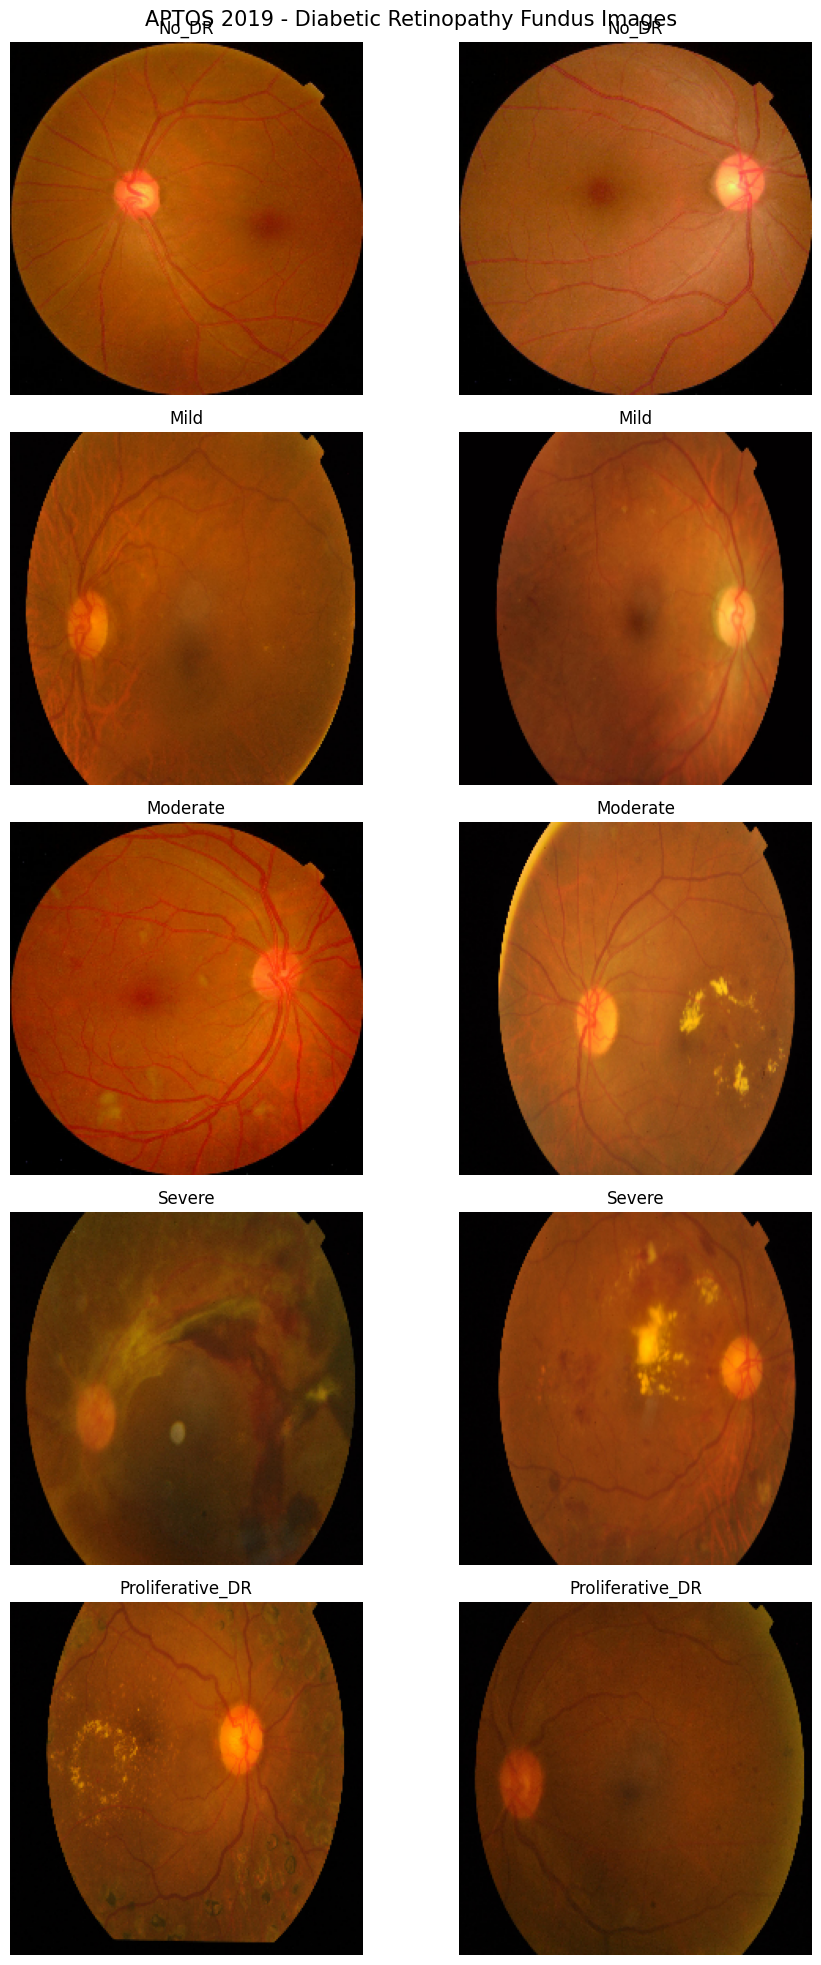


TRAINING CLASS DISTRIBUTION
diagnosis
0    1426
1     270
2     736
3     144
4     213
Name: count, dtype: int64


In [14]:

import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

# Diagnosis labels
class_names = {
    0: "No_DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative_DR"
}

# Display two images from each class
fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for class_id in range(5):

    class_df = train_clean[
        train_clean["diagnosis"] == class_id
    ]

    samples = class_df.sample(
        n=min(2, len(class_df)),
        random_state=42
    )

    for column, (_, row) in enumerate(samples.iterrows()):

        image = tf.io.read_file(row["image_path"])
        image = tf.io.decode_image(image, channels=3)
        image = tf.image.resize(image, (224, 224))

        axes[class_id, column].imshow(
            tf.cast(image, tf.uint8).numpy()
        )

        axes[class_id, column].set_title(
            class_names[class_id]
        )

        axes[class_id, column].axis("off")

    # Hide unused subplot if a class has fewer than 2 images
    for column in range(len(samples), 2):
        axes[class_id, column].axis("off")

plt.suptitle(
    "APTOS 2019 - Diabetic Retinopathy Fundus Images",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Display training class distribution
print("\nTRAINING CLASS DISTRIBUTION")
print(train_clean["diagnosis"].value_counts().sort_index())


steps for calculating class weight

In [15]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import pandas as pd

# Extract training labels
y_train = train_clean["diagnosis"].astype(int).values

# Define all five classes
classes = np.array([0, 1, 2, 3, 4])

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Create dictionary for model training
class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

# Display class weights
class_names = {
    0: "No_DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative_DR"
}

weight_table = pd.DataFrame({
    "Class": classes,
    "Diagnosis": [class_names[i] for i in classes],
    "Image_Count": [
        int(np.sum(y_train == i)) for i in classes
    ],
    "Class_Weight": weights
})

print("CLASS WEIGHT CALCULATION")
print("========================")
print(weight_table.to_string(index=False))

print("\nCLASS WEIGHTS FOR MODEL TRAINING:")
print(class_weights)

print("\nSUCCESS: CLASS WEIGHTS CALCULATED")


CLASS WEIGHT CALCULATION
 Class        Diagnosis  Image_Count  Class_Weight
     0            No_DR         1426      0.391164
     1             Mild          270      2.065926
     2         Moderate          736      0.757880
     3           Severe          144      3.873611
     4 Proliferative_DR          213      2.618779

CLASS WEIGHTS FOR MODEL TRAINING:
{0: 0.391164095371669, 1: 2.0659259259259257, 2: 0.7578804347826087, 3: 3.873611111111111, 4: 2.6187793427230046}

SUCCESS: CLASS WEIGHTS CALCULATED


reloading pretrained ImageNet weights

In [16]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# ==========================================
# 1. CONFIGURATION
# ==========================================

IMG_SIZE = (224, 224)
NUM_CLASSES = 5

print("Building MobileNetV3Small...")
print("TensorFlow:", tf.__version__)

# ==========================================
# 2. LOAD PRETRAINED MOBILENETV3SMALL
# ==========================================

base_model = tf.keras.applications.MobileNetV3Small(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=True
)

# Freeze the pretrained feature extractor
base_model.trainable = False

# ==========================================
# 3. ADD CLASSIFICATION HEAD
# ==========================================

inputs = layers.Input(shape=(224, 224, 3))

# Extract image features
x = base_model(inputs, training=False)

# Reduce feature dimensions
x = layers.GlobalAveragePooling2D()(x)

# Dropout for regularization
x = layers.Dropout(0.3)(x)

# Five-class classification
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classification_output"
)(x)

# Create final model
model = Model(
    inputs=inputs,
    outputs=outputs,
    name="MobileNetV3Small_DR"
)

# ==========================================
# 4. COMPILE MODEL
# ==========================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================
# 5. DISPLAY MODEL INFORMATION
# ==========================================

model.summary()

print("\nMODEL INFORMATION")
print("----------------------------")
print("Architecture: MobileNetV3Small")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Number of classes:", NUM_CLASSES)
print("Total parameters:", model.count_params())
print("Trainable parameters:",
      sum(tf.size(w).numpy() for w in model.trainable_weights))
print("Non-trainable parameters:",
      sum(tf.size(w).numpy() for w in model.non_trainable_weights))

print("\nSUCCESS: MOBILENETV3SMALL MODEL BUILT")


Building MobileNetV3Small...
TensorFlow: 2.21.0
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV3Small_DR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 5)              │         2,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 942,005 (3.59 MB)

 Trainable params: 2,885 (11.27 KB)

 Non-trainable params: 939,120 (3.58 MB)


MODEL INFORMATION
----------------------------
Architecture: MobileNetV3Small
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Number of classes: 5
Total parameters: 942005
Trainable parameters: 2885
Non-trainable parameters: 939120

SUCCESS: MOBILENETV3SMALL MODEL BUILT
